# Numerical Evolution of a Spherically Symmetric Black Hole

## Homework 5 — Gravitational-Wave Course

 ### Exercise 4

This notebook implements the numerical evolution of a Schwarzschild black hole using the Arnowitt–Deser–Misner (ADM) formulation in spherical symmetry.

The evolution equations are solved using the **Method of Lines**: fourth-order finite differences for spatial derivatives, and a fourth-order Runge–Kutta (RK4) integrator for time evolution.

The initial data correspond to a Schwarzschild black hole in isotropic coordinates. We use a static puncture treatment to factor out the analytically known conformal factor and evolve regularized variables.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=8, suppress=True)

In [ ]:
# Physical parameter
M = 1.0

# Radial domain
r_L = 0.0
r_R = 100.0

# Numerical resolution
dr = 0.01
dt = 0.5 * dr

# Evolution interval
t_initial = 0.0
t_final = 3.5

# Analytically expected crash time
t_expected = np.pi * M

print("Physical parameters")
print("-------------------")
print(f"Mass M = {M}")
print(f"Expected crash time (pi M) = {t_expected:.10f}")

print("\nNumerical parameters")
print("--------------------")
print(f"Radial domain = [{r_L}, {r_R}]")
print(f"Spatial resolution dr = {dr}")
print(f"Time step dt = {dt}")
print(f"Final evolution time = {t_final}")

Physical parameters
-------------------
Mass M = 1.0
Expected crash time (pi M) = 3.1415926536

Numerical parameters
--------------------
Radial domain = [0.0, 100.0]
Spatial resolution dr = 0.01
Time step dt = 0.005
Final evolution time = 3.5


In [ ]:
# Construction of the grid

# Number of radial grid points
N = int(round((r_R - r_L) / dr)) + 1

# Radial grid
r = np.linspace(r_L, r_R, N)

# Actual grid spacing
dr = r[1] - r[0]

print("Grid information")
print("----------------")
print("Number of grid points:", N)
print("First radial point:", r[0])
print("Last radial point:", r[-1])
print("Actual grid spacing:", dr)

Grid information
----------------
Number of grid points: 10001
First radial point: 0.0
Last radial point: 100.0
Actual grid spacing: 0.01


In [ ]:
# Initial conditions


# Initial metric variables (ecs 35-36)
A_tilde = np.ones(N)
B_tilde = np.ones(N)

# Initial auxiliary variables
D_A = np.zeros(N)
D_B = np.zeros(N)

# Initial extrinsic curvature
K_A = np.zeros(N)
K_B = np.zeros(N)

# Initial state vector
U_initial = np.array([
    A_tilde,
    B_tilde,
    D_A,
    D_B,
    K_A,
    K_B
])

print("Initial state shape:", U_initial.shape)
print("All values finite:", np.all(np.isfinite(U_initial)))

Initial state shape: (6, 10001)
All values finite: True


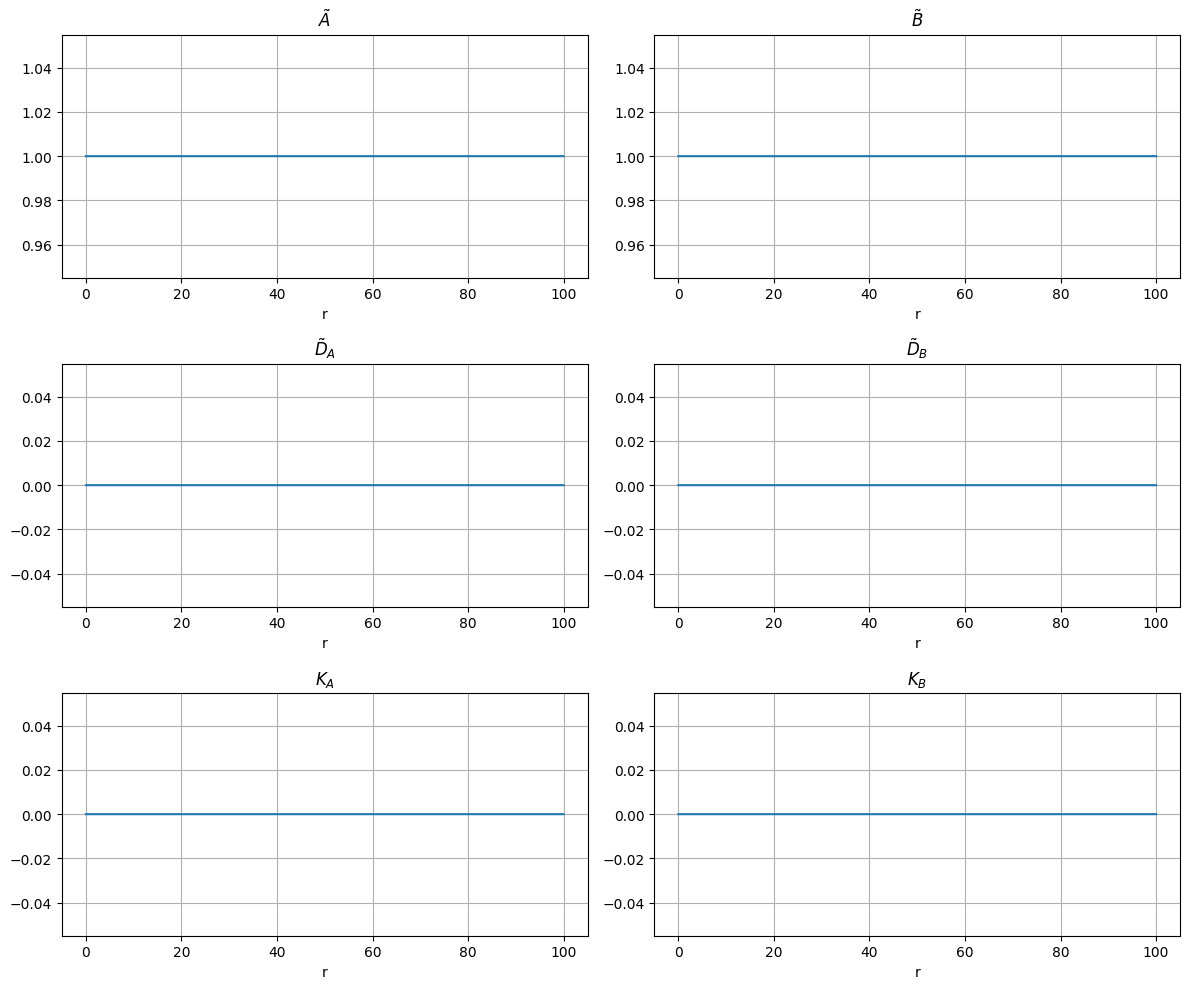

In [ ]:
#Plotting the initial conditions

variables = [
    r"$\tilde A$",
    r"$\tilde B$",
    r"$\tilde D_A$",
    r"$\tilde D_B$",
    r"$K_A$",
    r"$K_B$"
]

fig, axes = plt.subplots(3, 2, figsize=(12, 10))

for i, ax in enumerate(axes.flat):
    ax.plot(r, U_initial[i])
    ax.set_title(variables[i])
    ax.set_xlabel("r")
    ax.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
def add_inner_ghost_points(f, parity):
    """
    Add two ghost points at the inner boundary r = 0.

    Parameters
    ----------
    f : array
        Radial function defined on r >= 0.
    parity : str
        'even' or 'odd'.

    Returns
    -------
    f_ext : array
        Extended array including two ghost points.
    """

    f = np.asarray(f, dtype=float)

    if parity == "even":
        ghost_left = np.array([f[2], f[1]])

    elif parity == "odd":
        ghost_left = np.array([-f[2], -f[1]])

    else:
        raise ValueError("Parity must be 'even' or 'odd'.")

    return np.concatenate([ghost_left, f])

In [ ]:
# Test the parity conditions at the origin

f_even = r**2
f_odd = r**3

f_even_ext = add_inner_ghost_points(f_even, "even")
f_odd_ext = add_inner_ghost_points(f_odd, "odd")

print("Even function:")
print("Ghost points:", f_even_ext[:2])

print("\nOdd function:")
print("Ghost points:", f_odd_ext[:2])

Even function:
Ghost points: [0.0004 0.0001]

Odd function:
Ghost points: [-0.000008 -0.000001]


In [ ]:
test_even = np.array([0.0, 1.0, 4.0, 9.0, 16.0])
test_odd = np.array([0.0, 1.0, 2.0, 3.0, 4.0])

print("Even function:")
print(add_inner_ghost_points(test_even, "even"))

print("\nOdd function:")
print(add_inner_ghost_points(test_odd, "odd"))

Even function:
[ 4.  1.  0.  1.  4.  9. 16.]

Odd function:
[-2. -1.  0.  1.  2.  3.  4.]


In [ ]:
def radial_derivative(f, dr, parity):
    """
    Compute the radial derivative (spatial derivative) using fourth-order finite differences.
    """

# We convert the function into a numerical array, add the two ghost points at the origin, and set aside an array to store the derivatives.
    f = np.asarray(f, dtype=float)
    N = len(f)

    f_ext = add_inner_ghost_points(f, parity)
    df = np.zeros_like(f)

    # Centered fourth-order finite differences
    for i in range(N - 2):
        j = i + 2
        df[i] = (
            f_ext[j-2] - 8.0*f_ext[j-1]
            + 8.0*f_ext[j+1] - f_ext[j+2]
        ) / (12.0*dr)

    # Fourth-order stencil at the penultimate point
    i = N - 2
    df[i] = (
        -f[i-3]/12.0
        + f[i-2]/2.0
        - 3.0*f[i-1]/2.0
        + 5.0*f[i]/6.0
        + f[i+1]/4.0
    ) / dr

    # Fourth-order backward finite differences at the outer boundary
    df[-1] = (
        25.0*f[-1] - 48.0*f[-2]
        + 36.0*f[-3] - 16.0*f[-4]
        + 3.0*f[-5]
    ) / (12.0*dr)

    return df

In [ ]:
# # Test the fourth-order radial derivative


# Odd function
f_odd = np.sin(0.1*r)
df_odd_num = radial_derivative(f_odd, dr, "odd")
df_odd_exact = 0.1*np.cos(0.1*r)

# Even function
f_even = np.cos(0.1*r)
df_even_num = radial_derivative(f_even, dr, "even")
df_even_exact = -0.1*np.sin(0.1*r)

# Absolute errors
error_odd = np.abs(df_odd_num - df_odd_exact)
error_even = np.abs(df_even_num - df_even_exact)

print("Odd function:")
print("Maximum absolute error:", np.max(error_odd))
print("Error at the origin:", error_odd[0])
print("Error at the outer boundary:", error_odd[-1])

print("\nEven function:")
print("Maximum absolute error:", np.max(error_even))
print("Error at the origin:", error_even[0])
print("Error at the outer boundary:", error_even[-1])

Odd function:
Maximum absolute error: 4.900524430695441e-13
Error at the origin: 3.3306690738754696e-15
Error at the outer boundary: 4.900524430695441e-13

Even function:
Maximum absolute error: 3.267525139349914e-13
Error at the origin: 9.251858538542972e-16
Error at the outer boundary: 3.267525139349914e-13


In [ ]:
#Spatial derivatives of ADM variables
def compute_spatial_derivatives(K_A, K_B, D_B, dr):

    dK_A_dr = radial_derivative(K_A, dr, "even")
    dK_B_dr = radial_derivative(K_B, dr, "even")
    dD_B_dr = radial_derivative(D_B, dr, "odd")

    return dK_A_dr, dK_B_dr, dD_B_dr

In [ ]:
# Testing function: Evaluating the derivatives with respect to the initial data

dK_A_dr, dK_B_dr, dD_B_dr = compute_spatial_derivatives(
    K_A, K_B, D_B, dr
)

print("Maximum |dK_A/dr|:", np.max(np.abs(dK_A_dr)))
print("Maximum |dK_B/dr|:", np.max(np.abs(dK_B_dr)))
print("Maximum |dD_B/dr|:", np.max(np.abs(dD_B_dr)))

Maximum |dK_A/dr|: 0.0
Maximum |dK_B/dr|: 0.0
Maximum |dD_B/dr|: 0.0


In [ ]:
# Evolution equations for the metric and auxiliary variables (26-29)

def metric_rhs(A_tilde, B_tilde, K_A, K_B,
               dK_A_dr, dK_B_dr):

    dA_tilde_dt = -2.0 * A_tilde * K_A
    dB_tilde_dt = -2.0 * B_tilde * K_B

    dD_A_dt = -2.0 * dK_A_dr
    dD_B_dt = -2.0 * dK_B_dr

    return (
        dA_tilde_dt,
        dB_tilde_dt,
        dD_A_dt,
        dD_B_dt
    )

In [ ]:
# Testing

rhs_metric = metric_rhs(
    A_tilde, B_tilde,
    K_A, K_B,
    dK_A_dr, dK_B_dr
)

names = [
    "dA_tilde/dt",
    "dB_tilde/dt",
    "dD_A/dt",
    "dD_B/dt"
]

for name, value in zip(names, rhs_metric):
    print(f"{name}: max |value| = {np.max(np.abs(value))}")

dA_tilde/dt: max |value| = 0.0
dB_tilde/dt: max |value| = 0.0
dD_A/dt: max |value| = 0.0
dD_B/dt: max |value| = 0.0


In [ ]:
# Evolution equation for K_A - Ec (30-31)

def rhs_KA(r, M, A_tilde, D_A, D_B,
           K_A, K_B, dD_B_dr):

    term1 = K_A * (K_A + 2.0*K_B)

    term2 = 8.0*r**3 / (A_tilde*(M + 2.0*r)**6)

    term3 = (
        8.0*r*(M + 2.0*r)*D_B
        + r*(M + 2.0*r)**2*D_B**2
        - (M + 2.0*r)*D_A
        * (-2.0*M + 4.0*r + r*(M + 2.0*r)*D_B)
        + 2.0*(8.0*M + r*(M + 2.0*r)**2*dD_B_dr)
    )

    return term1 - term2*term3

In [ ]:
# Evolution equation pfor K_B - Ec (32-34)

def rhs_KB(r, M, A_tilde, B_tilde, D_A, D_B,
           K_A, K_B, dD_B_dr):

    # First term
    term1 = K_B * (K_A + 2.0*K_B)

    # Second term
    term2 = 16.0*r**2 / (B_tilde*(M + 2.0*r)**4)

    # Geometric expression inside the parentheses
    term3 = (
        r*(M + 2.0*r)*D_A
        * (-2.0*M + 4.0*r + r*(M + 2.0*r)*D_B)
        - 2.0*(
            2.0*(M**2 + 4.0*r**2)
            + 2.0*r*(-M**2 + 2.0*M*r + 8.0*r**2)*D_B
            + r**2*(M + 2.0*r)**2*D_B**2
            + r**2*(M + 2.0*r)**2*dD_B_dr
        )
    )

    # Fourth term
    term4 = 4.0*r**2 / (A_tilde*(M + 2.0*r)**6)

    return term1 + term2 + term4*term3

In [ ]:
# Evaluate the extrinsic curvature equations

dK_A_dt = rhs_KA(
    r, M, A_tilde, D_A, D_B,
    K_A, K_B, dD_B_dr
)

dK_B_dt = rhs_KB(
    r, M, A_tilde, B_tilde, D_A, D_B,
    K_A, K_B, dD_B_dr
)

print("Maximum |dK_A/dt|:", np.max(np.abs(dK_A_dt)))
print("Maximum |dK_B/dt|:", np.max(np.abs(dK_B_dt)))

print("\nAt the origin:")
print("dK_A/dt =", dK_A_dt[0])
print("dK_B/dt =", dK_B_dt[0])

Maximum |dK_A/dt|: 0.25
Maximum |dK_B/dt|: 0.125

At the origin:
dK_A/dt = 0.0
dK_B/dt = 0.0


#(a) Implement functions evaluating the ADM evolution equations
### Using Finite Difference Method

In [ ]:
# Function of the six ADM variables, including the external boundary

def adm_rhs(U, t, r, M, dr):

    A_tilde, B_tilde, D_A, D_B, K_A, K_B = U

    dK_A_dr, dK_B_dr, dD_B_dr = compute_spatial_derivatives(
        K_A, K_B, D_B, dr
    )

    rhs_A, rhs_B, rhs_DA, rhs_DB = metric_rhs(
        A_tilde, B_tilde,
        K_A, K_B,
        dK_A_dr, dK_B_dr
    )

    rhs_KA_value = rhs_KA(
        r, M, A_tilde, D_A, D_B,
        K_A, K_B, dD_B_dr
    )

    rhs_KB_value = rhs_KB(
        r, M, A_tilde, B_tilde, D_A, D_B,
        K_A, K_B, dD_B_dr
    )

    rhs = np.array([
        rhs_A,
        rhs_B,
        rhs_DA,
        rhs_DB,
        rhs_KA_value,
        rhs_KB_value
    ])

    # Enforce the outer boundary at r = r_R
    rhs[:, -1] = 0.0

    return rhs

In [ ]:
#Testing

rhs_initial = adm_rhs(U_initial, t_initial, r, M, dr)

print("Shape of ADM RHS:", rhs_initial.shape)
print("All values finite:", np.all(np.isfinite(rhs_initial)))

for name, value in zip(
    ["A_tilde", "B_tilde", "D_A", "D_B", "K_A", "K_B"],
    rhs_initial
):
    print(f"{name}: max |RHS| = {np.max(np.abs(value))}")

print("\nOuter boundary:")
print("RHS at outer boundary:", rhs_initial[:, -1])

Shape of ADM RHS: (6, 10001)
All values finite: True
A_tilde: max |RHS| = 0.0
B_tilde: max |RHS| = 0.0
D_A: max |RHS| = 0.0
D_B: max |RHS| = 0.0
K_A: max |RHS| = 0.25
K_B: max |RHS| = 0.125

Outer boundary:
RHS at outer boundary: [0. 0. 0. 0. 0. 0.]


# Starting section (b)

In [ ]:
# Runge -Kutta Method (Following eqs. 2 - 7 from exercise 2)

def rk4(F, U, t, dt, *args):

    k1 = F(U, t, *args)

    k2 = F(
        U + 0.5*dt*k1,
        t + 0.5*dt,
        *args
    )

    k3 = F(
        U + 0.5*dt*k2,
        t + 0.5*dt,
        *args
    )

    k4 = F(
        U + dt*k3,
        t + dt,
        *args
    )

    return U + (dt/6.0)*(k1 + 2*k2 + 2*k3 + k4)

In [ ]:
# Testing RK4 with harmonic oscillator

def harmonic_oscillator(U, t):
    return np.array([U[1], -4.0*U[0]])


U_osc = np.array([1.0, 0.0])

dt_test = 0.01
t_test = 1.0

n_steps = int(t_test/dt_test)

for n in range(n_steps):
    U_osc = rk4(
        harmonic_oscillator,
        U_osc,
        n*dt_test,
        dt_test
    )

U_exact = np.array([
    np.cos(2.0*t_test),
    -2.0*np.sin(2.0*t_test)
])

print("Numerical solution:", U_osc)
print("Exact solution:", U_exact)
print("Absolute error:", np.abs(U_osc-U_exact))

Numerical solution: [-0.41614683 -1.81859486]
Exact solution: [-0.41614684 -1.81859485]
Absolute error: [0. 0.]


In [ ]:
# Testing the boundary

rhs_initial = adm_rhs(U_initial, t_initial, r, M, dr)

print("RHS at outer boundary:")
print(rhs_initial[:, -1])

print("\nInitial values at outer boundary:")
print(U_initial[:, -1])

RHS at outer boundary:
[0. 0. 0. 0. 0. 0.]

Initial values at outer boundary:
[1. 1. 0. 0. 0. 0.]


In [ ]:
# Test: One step - evolution

U_test = rk4(
    adm_rhs,
    U_initial,
    t_initial,
    dt,
    r, M, dr
)

print("Shape:", U_test.shape)
print("All values finite:", np.all(np.isfinite(U_test)))

names = [
    "A_tilde", "B_tilde", "D_A",
    "D_B", "K_A", "K_B"
]

for name, values in zip(names, U_test):
    print(
        f"{name}: min = {np.min(values):.8e}, "
        f"max = {np.max(values):.8e}"
    )

print("\nOuter boundary after one RK4 step:")
print(U_test[:, -1])

print("\nDifference from initial boundary values:")
print(U_test[:, -1] - U_initial[:, -1])

Shape: (6, 10001)
All values finite: True
A_tilde: min = 1.00000000e+00, max = 1.00000625e+00
B_tilde: min = 9.99996875e-01, max = 1.00000000e+00
D_A: min = -4.64152430e-06, max = 2.40962275e-05
D_B: min = -1.20481272e-05, max = 2.32076804e-06
K_A: min = -1.24999935e-03, max = 0.00000000e+00
K_B: min = 0.00000000e+00, max = 6.25001628e-04

Outer boundary after one RK4 step:
[1. 1. 0. 0. 0. 0.]

Difference from initial boundary values:
[0. 0. 0. 0. 0. 0.]


##### Note: Initially, the metric variables are constant and the extrinsic curvatures are zero. After the first time step, the curvatures begin to evolve, and the metric variables respond to them.

In [ ]:
# Complete temporal evolution

U = U_initial.copy()

t = t_initial
time_history = []
max_values_history = []

crash_time = None

n_steps = int(np.ceil((t_final - t_initial)/dt))

for n in range(n_steps):

    U_new = rk4(adm_rhs, U, t, dt, r, M, dr)

    if not np.all(np.isfinite(U_new)):
        crash_time = t + dt
        print(f"Numerical failure at t = {crash_time:.8f}")
        break

    U = U_new
    t += dt

    time_history.append(t)
    max_values_history.append(
        np.max(np.abs(U), axis=1)
    )

    if n % 100 == 0:
        print(f"Step {n:5d} | t = {t:.4f}")

if crash_time is None:
    print("No numerical failure detected.")

Step     0 | t = 0.0050
Step   100 | t = 0.5050
Step   200 | t = 1.0050
Step   300 | t = 1.5050
Step   400 | t = 2.0050
Step   500 | t = 2.5050
Step   600 | t = 3.0050
Numerical failure at t = 3.15500000


/tmp/ipykernel_43726/1868427688.py:6: RuntimeWarning: overflow encountered in multiply
  dA_tilde_dt = -2.0 * A_tilde * K_A
/tmp/ipykernel_43726/1868427688.py:7: RuntimeWarning: overflow encountered in multiply
  dB_tilde_dt = -2.0 * B_tilde * K_B
/tmp/ipykernel_43726/1590880960.py:17: RuntimeWarning: invalid value encountered in scalar subtract
  f_ext[j-2] - 8.0*f_ext[j-1]
/tmp/ipykernel_43726/1590880960.py:17: RuntimeWarning: invalid value encountered in scalar add
  f_ext[j-2] - 8.0*f_ext[j-1]
/tmp/ipykernel_43726/3238506310.py:6: RuntimeWarning: invalid value encountered in add
  term1 = K_A * (K_A + 2.0*K_B)
/tmp/ipykernel_43726/3238506310.py:12: RuntimeWarning: overflow encountered in square
  + r*(M + 2.0*r)**2*D_B**2
/tmp/ipykernel_43726/3238506310.py:13: RuntimeWarning: overflow encountered in multiply
  - (M + 2.0*r)*D_A
/tmp/ipykernel_43726/3238506310.py:18: RuntimeWarning: invalid value encountered in multiply
  return term1 - term2*term3
/tmp/ipykernel_43726/3783758308.py

In [ ]:
# Analyzing the last valid moment
print("Last finite time:", t)
print("Detected failure time:", crash_time)

names = [
    "A_tilde",
    "B_tilde",
    "D_A",
    "D_B",
    "K_A",
    "K_B"
]

print("\nMaximum absolute value of each variable:")

for name, values in zip(names, U):
    print(f"{name}: {np.max(np.abs(values)):.8e}")

Last finite time: 3.149999999999955
Detected failure time: 3.154999999999955

Maximum absolute value of each variable:
A_tilde: 1.69419534e+72
B_tilde: 4.54599373e+67
D_A: 7.49827249e+36
D_B: 1.47138281e+37
K_A: 1.10991934e+73
K_B: 2.17798999e+73


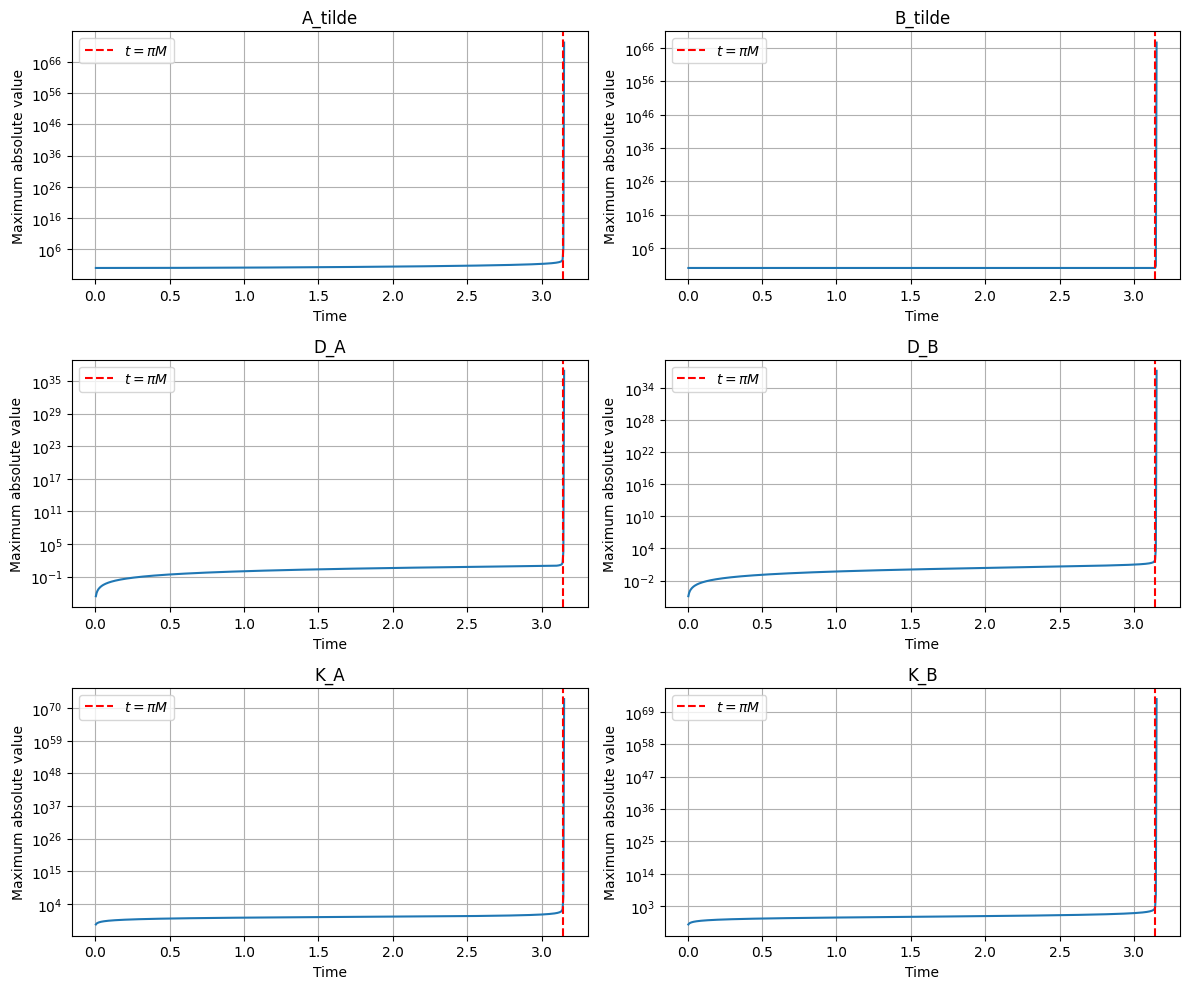

In [ ]:
# visualizing how the six variables grow during the simulation.

time_history = np.array(time_history)
max_values_history = np.array(max_values_history)

fig, axes = plt.subplots(3, 2, figsize=(12, 10))

for i, ax in enumerate(axes.flat):
    ax.semilogy(
        time_history,
        max_values_history[:, i]
    )

    ax.axvline(
        np.pi*M,
        color="red",
        linestyle="--",
        label=r"$t=\pi M$"
    )

    ax.set_title(names[i])
    ax.set_xlabel("Time")
    ax.set_ylabel("Maximum absolute value")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

## Explanation:
The three preceding cells exhibit the behavior expected according to the parameters set out in the exercise. With the choice of $M=1$, the crash time occurs at **$t=\pi = 3.1415$...**

A possible explanation is the development of a coordinate singularity associated with the temporal foliation (geodesic slicing): $\alpha=1$ and $\beta^i=0$.

Convergence remains to be studied.

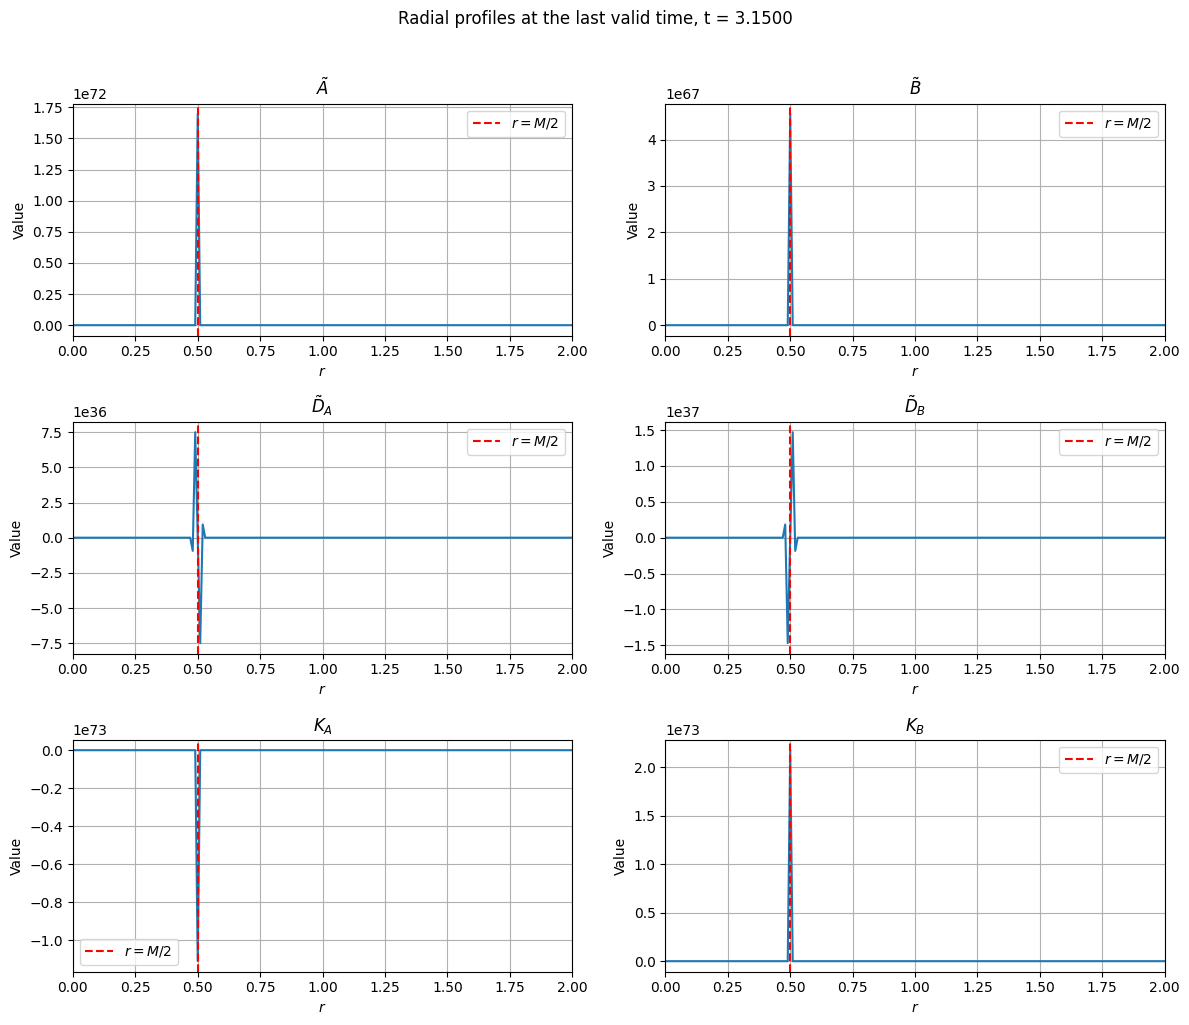

In [ ]:
# Radial profiles at the last valid instant

fig, axes = plt.subplots(3, 2, figsize=(12, 10))

names = [
    r"$\tilde A$",
    r"$\tilde B$",
    r"$\tilde D_A$",
    r"$\tilde D_B$",
    r"$K_A$",
    r"$K_B$"
]

for i, ax in enumerate(axes.flat):

    ax.plot(r, U[i])

    ax.axvline(
        M/2,
        color="red",
        linestyle="--",
        label=r"$r=M/2$"
    )

    ax.set_xlim(0, 2)
    ax.set_title(names[i])
    ax.set_xlabel(r"$r$")
    ax.set_ylabel("Value")
    ax.grid(True)
    ax.legend()

plt.suptitle(
    f"Radial profiles at the last valid time, t = {t:.4f}",
    y=1.02
)

plt.tight_layout()
plt.show()

In [ ]:
# Locating the maximum of each variable
for i, name in enumerate(names):

    index_max = np.argmax(np.abs(U[i]))

    print(
        f"{name}: "
        f"maximum at r = {r[index_max]:.5f}, "
        f"value = {U[i, index_max]:.8e}"
    )

$\tilde A$: maximum at r = 0.50000, value = 1.69419534e+72
$\tilde B$: maximum at r = 0.50000, value = 4.54599373e+67
$\tilde D_A$: maximum at r = 0.51000, value = -7.49827249e+36
$\tilde D_B$: maximum at r = 0.51000, value = 1.47138281e+37
$K_A$: maximum at r = 0.50000, value = -1.10991934e+73
$K_B$: maximum at r = 0.50000, value = 2.17798999e+73


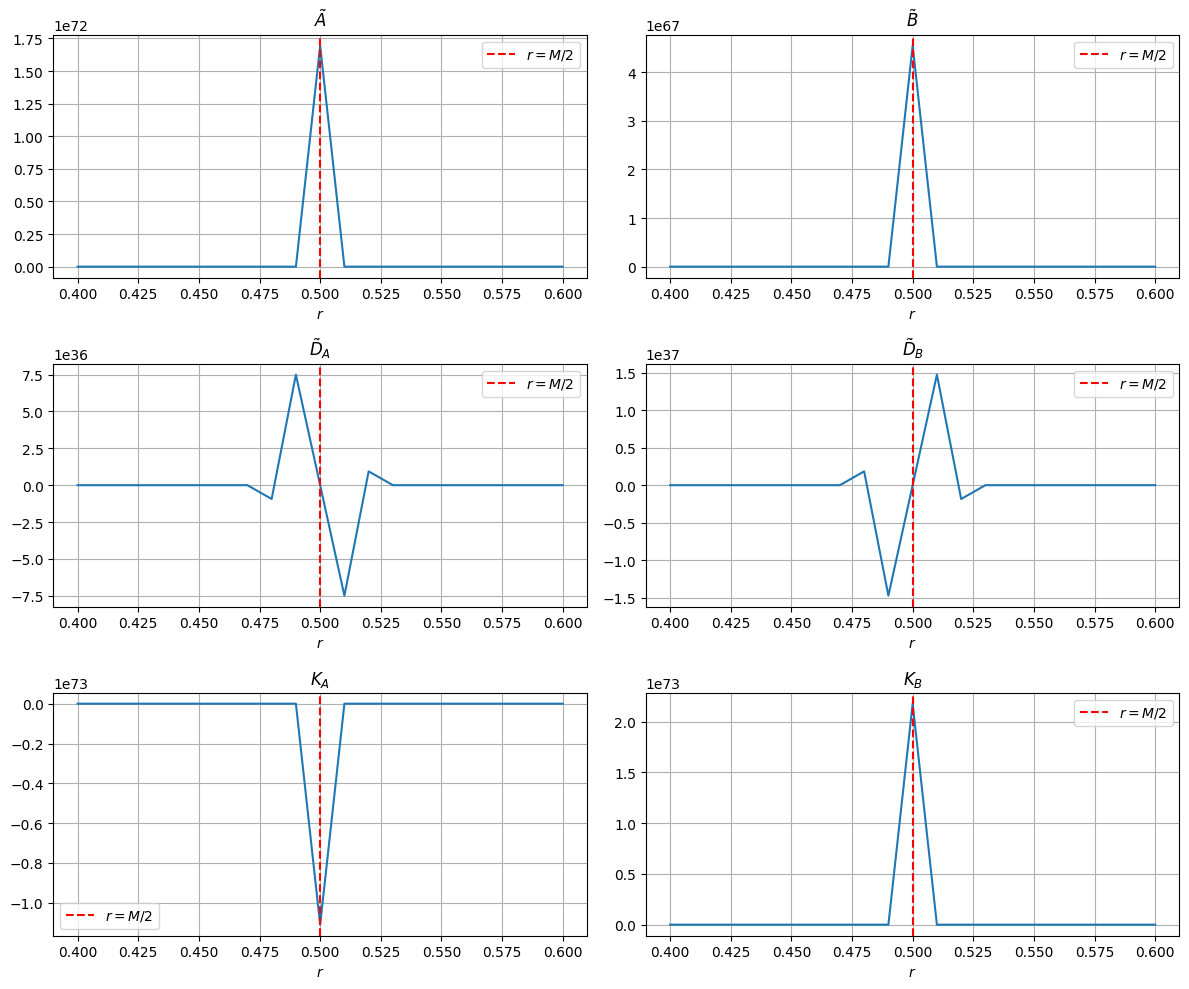

In [ ]:
# Examining the horizon region r_H=0.5

r_horizon = M / 2.0

window = 0.10

mask = np.abs(r - r_horizon) <= window

fig, axes = plt.subplots(3, 2, figsize=(12, 10))

names = [
    r"$\tilde A$",
    r"$\tilde B$",
    r"$\tilde D_A$",
    r"$\tilde D_B$",
    r"$K_A$",
    r"$K_B$"
]

for i, ax in enumerate(axes.flat):

    ax.plot(r[mask], U[i][mask])
    ax.axvline(
        r_horizon,
        color="red",
        linestyle="--",
        label=r"$r=M/2$"
    )

    ax.set_title(names[i])
    ax.set_xlabel(r"$r$")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

### Radial localization of the numerical growth (graphs explanation)

The radial profiles at the last finite time show that the growth of all six
evolved variables is strongly localized around $r=M/2$ (for $M=1$, $r=0.5$), which corresponds
to the isotropic-coordinate location of the Schwarzschild BH horizon.

The metric variables ($\tilde A$) and ($\tilde B$), as well as the extrinsic
curvature components ($K_A$) and ($K_B$), develop extremely large values
near this location. The auxiliary variables ($\tilde D_A$) and ($\tilde D_B$)
also exhibit large variations and changes of sign in the same region.

This behavior suggests a localized numerical breakdown near the horizon.
It does not, by itself, indicate a physical singularity, but may be related
to the chosen geodesic slicing ($\alpha=1$), ($\beta^i=0$).

# (b) Verify the convergence of the failure time

In [ ]:
# Automating the numerical evolution.
# The function takes the spatial resolution as input and return the detected failure time.

#We will implement checks for excessive growth, as well as detection of NaNs and infinities.
#The simulation stops if any variable exceeds the prescribed threshold

#Constructing the function:

#dr_sim = spatial resolution; M = BH mass; r_R= exterior radious in the domain; safety_factor= temporal step factor; t_max= max time evolution

def run_simulation(dr_sim, M=1.0, r_R=100.0,
                   safety_factor=0.5, t_max=3.5,
                   threshold=1e10):

    r_sim = np.linspace(                        #Constructing the radial grid from 0 to r_R
        0.0, r_R,
        int(round(r_R/dr_sim)) + 1              # +1 to include the extreme points
    )

    dr_sim = r_sim[1] - r_sim[0]                #  spatial and temporal steps
    dt_sim = safety_factor * dr_sim             #   For us C=safety_factor = 0.5

    N_sim = len(r_sim)                          # Number of points in the grid

# Initialization the six ADM variables - Initial conditions

    U = np.zeros((6, N_sim))
    U[0] = 1.0
    U[1] = 1.0

# Initialization of the time (and steps)
    t = 0.0
    n_steps = int(np.ceil(t_max/dt_sim))

#Evolution of the system by rk4 method
    for n in range(n_steps):

        U_new = rk4(
            adm_rhs, U, t, dt_sim,
            r_sim, M, dr_sim
        )
# Detector of non-finite values - Numerical stabilization

        if not np.all(np.isfinite(U_new)):
            return t + dt_sim, "Non-finite values"

#Detector of exceeded growing
        max_value = np.max(np.abs(U_new))

        if max_value > threshold:
            return t + dt_sim, "Threshold exceeded"

        U = U_new
        t += dt_sim

    return None, "No failure detected"

### Testing with Δr = 0.01

In [ ]:
# Testing using \deltar=0.01

crash_time_test, status_test = run_simulation(
    dr_sim=0.01,
    M=M,
    r_R=r_R,
    safety_factor=0.5,
    t_max=3.5
)

print("Status:", status_test)
print("Crash time:", crash_time_test)
print("Expected time:", np.pi*M)

Status: Threshold exceeded
Crash time: 3.149999999999955
Expected time: 3.141592653589793


### Testing with different resolutions

In [ ]:
# Testing with different resolutions
resolutions = [0.02, 0.01, 0.005, 0.0025]

results = []

for dr_sim in resolutions:

    print(f"\nRunning simulation with dr = {dr_sim}")

    crash_time, status = run_simulation(
        dr_sim=dr_sim,
        M=1.0,
        r_R=100.0,
        safety_factor=0.5,
        t_max=3.5
    )

    results.append({
        "dr": dr_sim,
        "dt": 0.5*dr_sim,
        "crash_time": crash_time,
        "status": status
    })

    print("Status:", status)
    print("Crash time:", crash_time)


Running simulation with dr = 0.02
Status: Threshold exceeded
Crash time: 3.1599999999999766

Running simulation with dr = 0.01
Status: Threshold exceeded
Crash time: 3.149999999999955

Running simulation with dr = 0.005
Status: Threshold exceeded
Crash time: 3.144999999999944

Running simulation with dr = 0.0025
Status: Threshold exceeded
Crash time: 3.1437500000001415


In [ ]:
print(f"{'dr':>10} {'dt':>10} {'Crash time':>15} {'Status':>25}")

for result in results:

    print(
        f"{result['dr']:10.5f} "
        f"{result['dt']:10.5f} "
        f"{str(result['crash_time']):>15} "
        f"{result['status']:>25}"
    )

        dr         dt      Crash time                    Status
   0.02000    0.01000 3.1599999999999766        Threshold exceeded
   0.01000    0.00500 3.149999999999955        Threshold exceeded
   0.00500    0.00250 3.144999999999944        Threshold exceeded
   0.00250    0.00125 3.1437500000001415        Threshold exceeded


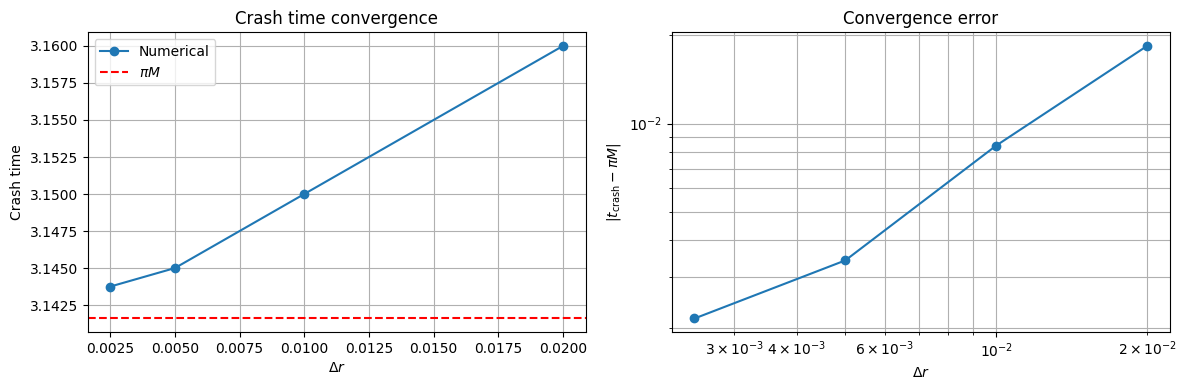

In [ ]:
# Plotting the convergence

dr_values = np.array([item["dr"] for item in results])
crash_times = np.array([item["crash_time"] for item in results])

errors = np.abs(crash_times - np.pi*M)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Crash time versus spatial resolution
axes[0].plot(dr_values, crash_times, "o-", label="Numerical")
axes[0].axhline(
    np.pi*M, color="red", linestyle="--",
    label=r"$\pi M$"
)
axes[0].set_xlabel(r"$\Delta r$")
axes[0].set_ylabel("Crash time")
axes[0].set_title("Crash time convergence")
axes[0].grid(True)
axes[0].legend()

# Error versus spatial resolution
axes[1].loglog(dr_values, errors, "o-")
axes[1].set_xlabel(r"$\Delta r$")
axes[1].set_ylabel(r"$|t_{\rm crash}-\pi M|$")
axes[1].set_title("Convergence error")
axes[1].grid(True, which="both")

plt.tight_layout()
plt.show()


In [ ]:
# Threshold sensitivity

thresholds = [1e8, 1e10, 1e12]
dr_values = [0.01, 0.005, 0.0025]

threshold_results = []

for threshold in thresholds:

    for dr_sim in dr_values:

        print(
            f"Threshold = {threshold:.0e}, "
            f"dr = {dr_sim}"
        )

        crash_time, status = run_simulation(
            dr_sim=dr_sim,
            M=1.0,
            r_R=100.0,
            safety_factor=0.5,
            t_max=3.5,
            threshold=threshold
        )

        threshold_results.append({
            "threshold": threshold,
            "dr": dr_sim,
            "crash_time": crash_time,
            "status": status
        })

        print("Crash time:", crash_time)

Threshold = 1e+08, dr = 0.01
Crash time: 3.149999999999955
Threshold = 1e+08, dr = 0.005
Crash time: 3.144999999999944
Threshold = 1e+08, dr = 0.0025
Crash time: 3.1425000000001413
Threshold = 1e+10, dr = 0.01
Crash time: 3.149999999999955
Threshold = 1e+10, dr = 0.005
Crash time: 3.144999999999944
Threshold = 1e+10, dr = 0.0025
Crash time: 3.1437500000001415
Threshold = 1e+12, dr = 0.01
Crash time: 3.149999999999955
Threshold = 1e+12, dr = 0.005
Crash time: 3.144999999999944
Threshold = 1e+12, dr = 0.0025


### Sensitivity to the numerical threshold

To verify that the detected failure time is not an artifact of the chosen numerical threshold, we repeat the simulations using three different values:
$(10^{8}), (10^{10})$, and $(10^{12})$.

The results show that the detected failure times remain practically unchanged when the threshold is varied, with only a difference of one time step for the finest resolution.

This indicates that the numerical breakdown is not strongly dependent on the threshold used to detect it. Together with the resolution study, these results provide evidence that the failure time converges toward the expected value

$t_{crash} = \pi M$

## Conclusion

The numerical evolution exhibits a rapid growth of the ADM variables near $t=\pi M$. By repeating the simulations with progressively finer spatial resolutions, we observe that the detected crash time approaches the expected value $t=\pi M$, providing evidence of convergence toward this value.

The growth is strongly localized around the isotropic Schwarzschild horizon, $r=M/2$. This suggests that the numerical breakdown may be associated with the chosen geodesic slicing $\alpha=1$, $\beta^i=0$, rather than indicating a physical singularity at the horizon.

Furthermore, varying the numerical threshold used to detect the breakdown produces nearly identical crash times, confirming that the observed convergence is not strongly dependent on this numerical criterion.